# Final Assignment - Part 2

### Assignment Instructions

#### Part 2   |   Advanced Difficulty Level

In this second part, you will be working with a datasets containing information on indian startups' funding, including the startup's details, the funding it received, and the investors' information. 

In the usual `data` folder, you will find the following three datasets, including data from 2019, 2020 and 2021: 

- `startup_funding2019.csv`
- `startup_funding2020.csv`
- `startup_funding2021.csv`

At [this link](https://www.kaggle.com/datasets/omkargowda/indian-startups-funding-data?select=startup_funding2019.csv) you can find the source of the original data (Kaggle) as well as more information on its composition *(note: the files in the data folder are slightly different from the originals)*.

1. Using a **for loop**, load all three .csv files in a temporary DataFrame called `df_tmp` and, at each cycle, add a new column named `Year` that includes the year of that csv file to the temporary table and append it to a final DataFrame named `fnd`. Your final `fnd` DataFrame should include the contents from all three csv files stacked one on top of the other. 

    What is the **shape** of the `fnd` DataFrame? 

In [2]:
import pandas as pd

files = [
    ('data/startup_funding2019.csv', 2019),
    ('data/startup_funding2020.csv', 2020),
    ('data/startup_funding2021.csv', 2021)
]

fnd = pd.DataFrame()

for filename, year in files:
    df_tmp = pd.read_csv(filename)
    
    df_tmp['Year'] = year
    
    fnd = pd.concat([fnd, df_tmp], ignore_index=True)

print(fnd.shape)

(2343, 10)


2. If you check the columns' data types, you'll notice that the columns `Founded`, `Amount($)` and `Year` are being interpreted as strings instead of numbers. Format those three columns to numeric data types. 

    What is the **total** `Amount($)` of funding given in the three years available?

In [3]:
fnd['Amount($)'] = fnd['Amount($)'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
fnd['Amount($)'] = pd.to_numeric(fnd['Amount($)'], errors='coerce')

fnd['Founded'] = pd.to_numeric(fnd['Founded'], errors='coerce')
fnd['Year'] = pd.to_numeric(fnd['Year'], errors='coerce')

total_amount = fnd['Amount($)'].sum()
print(total_amount)

271544633855.83002


3. The following code shows us that "Inflection Point Ventures" was the `Investor` that funded the highest number of `Company/Brand`s overall (36 companies funded from 2019 to 2021). 

    How did "Inflection Point Ventures" **rank** *(in terms of most `Company/Brand`s funded) **in 2020**? (Note: in the answer write the rank number, where 1 = most funded company)*

In [4]:
# run this cell (don not delete it)
fnd.groupby('Investor', as_index=False).size().sort_values('size', ascending=False).head(1)

,Investor,size
696,Inflection Point Ventures,36


In [8]:
fnd_2020 = fnd[fnd['Year'] == 2020]

investor_counts = fnd_2020['Investor'].value_counts()

rank = investor_counts.rank(method='min', ascending=False)['Inflection Point Ventures']
print(rank)

4.0


4. Load the `Software Professionals Salary.csv` file in a DataFrame named `sps` (just like you did in Part 1), then perform the following tasks **and answer the question at the end**: 
    1. starting from the `sps` DataFrame, create a new DF called `sps_loc` where you group by `Location` and show, for each city in the dataset, the average `Rating` and `Salary`;
    2. starting from the `fnd` DataFrame, create a new DF called `fnd_loc` where you group by `HeadQuarter` and show, for each city in the dataset **for the year 2021**, the total number of `Company/Brand`s funded and the total `Amount($)` invested;
    3. merge the two DataFrames you just created so to **keep just the cities that are in both datasets** and save the results in a third DataFrame called `sps_fnd_loc` *(note: make sure to use the correct type of join)*;
    4. using the `sps_fnd_loc` DataFrame: 
        1. delete the `HeadQuarter` column
        2. create a new column `Amount($MM)` that is equal to `Amount($)` divided by 1,000,000
        3. delete the `Amount($)` column
        4. rename all the columns to the following names: `['City', 'Avg. Rating', 'Avg. Salary', 'Nr. Companies Funded', 'Sum Funding ($MM)']`
    
    **Question**: Look at the `City` that received the **highest** `Avg. Rating` score by employees: what is the `Nr. Companies Funded` in that city? 

In [9]:
import pandas as pd

sps = pd.read_csv('data/Software Professionals Salary.csv')

sps_loc = sps.groupby('Location', as_index=False)[['Rating', 'Salary']].mean()

fnd_2021 = fnd[fnd['Year'] == 2021]
fnd_loc = fnd_2021.groupby('HeadQuarter', as_index=False).agg({
    'Company/Brand': 'count',
    'Amount($)': 'sum'
})

sps_fnd_loc = pd.merge(sps_loc, fnd_loc, left_on='Location', right_on='HeadQuarter', how='inner')

sps_fnd_loc.drop(columns=['HeadQuarter'], inplace=True)
sps_fnd_loc['Amount($MM)'] = sps_fnd_loc['Amount($)'] / 1000000
sps_fnd_loc.drop(columns=['Amount($)'], inplace=True)
sps_fnd_loc.columns = ['City', 'Avg. Rating', 'Avg. Salary', 'Nr. Companies Funded', 'Sum Funding ($MM)']

highest_rating_city = sps_fnd_loc.sort_values('Avg. Rating', ascending=False).iloc[0]
print(f"City: {highest_rating_city['City']}")
print(f"Nr. Companies Funded: {highest_rating_city['Nr. Companies Funded']}")

City: Kolkata
Nr. Companies Funded: 5


5. Create a scatterplot that shows the relationship between the `Avg. Salary` and the `Sum Funding ($MM)`. Which `City` stands out in terms of total funding received by companies and salary paid to their employees? 

        City  Avg. Rating    Avg. Salary  Nr. Companies Funded  \
5     Mumbai     3.881709  961180.368491                   200   
0  Bangalore     3.920232  735344.739593                   425   
6  New Delhi     3.943415  658756.735632                   143   
1    Chennai     3.902726  584559.661513                    40   
7       Pune     3.886082  690476.311153                    46   

   Sum Funding ($MM)  
5          153830.30  
0           14327.42  
6            1673.01  
1             717.14  
7             509.07  
        City  Avg. Rating    Avg. Salary  Nr. Companies Funded  \
5     Mumbai     3.881709  961180.368491                   200   
0  Bangalore     3.920232  735344.739593                   425   
4    Kolkata     4.024719  710925.573034                     5   
7       Pune     3.886082  690476.311153                    46   
2  Hyderabad     3.914484  679099.157376                    34   

   Sum Funding ($MM)  
5          153830.30  
0           14327.42  

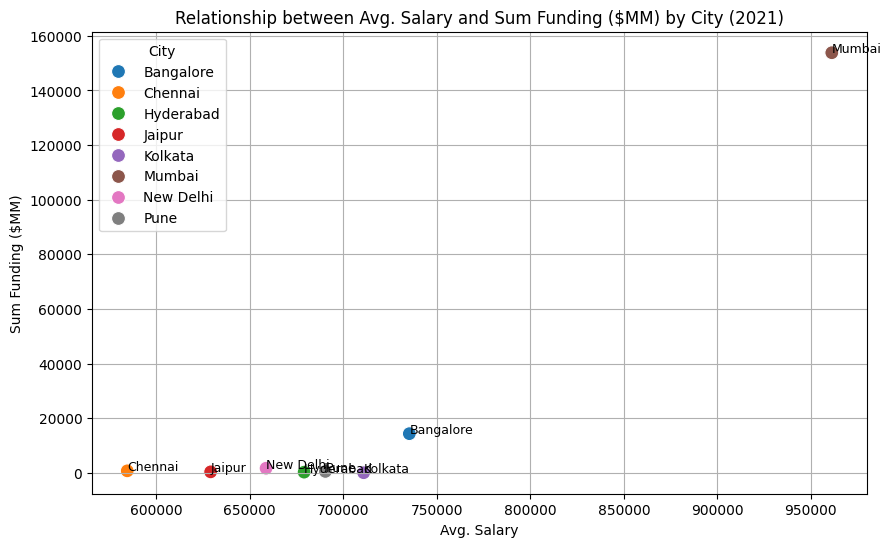

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

files = {
    '2019': 'data/startup_funding2019.csv',
    '2020': 'data/startup_funding2020.csv',
    '2021': 'data/startup_funding2021.csv'
}

fnd = pd.DataFrame()
for year, file in files.items():
    df_tmp = pd.read_csv(file)
    df_tmp['Year'] = int(year)
    fnd = pd.concat([fnd, df_tmp], ignore_index=True)

fnd['Amount($)'] = fnd['Amount($)'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
fnd['Amount($)'] = pd.to_numeric(fnd['Amount($)'], errors='coerce')

fnd_2021 = fnd[fnd['Year'] == 2021]

fnd_loc = fnd_2021.groupby('HeadQuarter', as_index=False).agg({
    'Company/Brand': 'count',
    'Amount($)': 'sum'
})

sps = pd.read_csv('data/Software Professionals Salary.csv')

sps_loc = sps.groupby('Location', as_index=False)[['Rating', 'Salary']].mean()

sps_fnd_loc = pd.merge(sps_loc, fnd_loc, left_on='Location', right_on='HeadQuarter', how='inner')

sps_fnd_loc = sps_fnd_loc.drop(columns=['HeadQuarter'])
sps_fnd_loc['Amount($MM)'] = sps_fnd_loc['Amount($)'] / 1_000_000
sps_fnd_loc = sps_fnd_loc.drop(columns=['Amount($)'])
sps_fnd_loc.columns = ['City', 'Avg. Rating', 'Avg. Salary', 'Nr. Companies Funded', 'Sum Funding ($MM)']

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sps_fnd_loc, x='Avg. Salary', y='Sum Funding ($MM)', hue='City', s=100)

for i in range(sps_fnd_loc.shape[0]):
    plt.text(
        sps_fnd_loc['Avg. Salary'][i]+0.2, 
        sps_fnd_loc['Sum Funding ($MM)'][i], 
        sps_fnd_loc['City'][i],
        fontdict={'size': 9}
    )

plt.title('Relationship between Avg. Salary and Sum Funding ($MM) by City (2021)')
plt.grid(True)
plt.savefig('salary_funding_scatter.png')

print(sps_fnd_loc.sort_values(by='Sum Funding ($MM)', ascending=False).head())
print(sps_fnd_loc.sort_values(by='Avg. Salary', ascending=False).head())